In [333]:
import pyranges as pr
import gzip
import pandas as pd
import numpy as np
from scipy.sparse import dok_matrix

from hicexplorer import hicConvertFormat
from hicexplorer import hicSumMatrices

import hicmatrix.HiCMatrix as hm
from hicexplorer import utilities
import scipy.sparse as sp

import tempfile
import copy

import pyBigWig
import gzip
from sklearn.preprocessing import MinMaxScaler
import random


In [336]:
path_interactions_E12_5_rep1 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.txt.gz"
path_interactions_E12_5_rep2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.txt.gz"

path_interactions_E14_5_rep1 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505216_Pinna_E14.5_CapHiC_Chicago_output_washU_text.txt.gz"
path_interactions_E14_5_rep2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505217_Pinna_E14.5_CapHiC_3rdBioRep_cd_washU_text.txt.gz"

path_output_bedpe_E12_5_rep1 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.bedpe"
path_output_bedpe_E12_5_rep2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.bedpe"

path_output_bedpe_E14_5_rep1 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505216_Pinna_E14.5_CapHiC_Chicago_output_washU_text.bedpe"
path_output_bedpe_E14_5_rep2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505217_Pinna_E14.5_CapHiC_3rdBioRep_cd_washU_text.bedpe"

path_output_cool_rep1 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505214_Pinna_E12.5_CapHiC_Chicago_output_washU_text.cool"
path_output_cool_rep2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505215_Pinna_E12.5_CapHiC_3rdBioRep_Merged_cd_washU_text.cool"

path_output_cool_merged = "/home/joachim/data/MHH/epigenetic_graph_analyzer/phic/GSM6505215_Pinna_E12.5_CapHiC_merged.cool"


path_mm10_chromosome_size = "/home/joachim/data/MHH/epigenetic_graph_analyzer/mm10.chrom.sizes"
path_promoter = "/home/joachim/data/MHH/epigenetic_graph_analyzer/mm10_promoter.bed"


path_histones_H3K3me2_rep1 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM6505186_H3K4me2_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K3me2_rep2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM6505187_H3K4me2_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27me3_rep1  = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM6505188_H3K27me3_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27me3_rep2  = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM6505189_H3K27me3_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_histones_H3K27ac_rep1  = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM6505184_H3K27ac_Pinna_E12.5_WT_rep1.scaled_0100.bw"
path_histones_H3K27ac_rep2  = "/home/joachim/data/MHH/epigenetic_graph_analyzer/histones/GSM6505185_H3K27ac_Pinna_E12.5_WT_rep2.scaled_0100.bw"

path_RNA_rep1 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/RNA/GSM6505221_RNAseq_E12.5-Pinna_TruSeq_1_cpm_100.bw"
path_RNA_rep2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/RNA/GSM6505222_RNAseq_E12.5-Pinna_TruSeq_2_cpm_100.bw"
path_RNA_rep3 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/RNA/GSM6505223_RNAseq_E12.5-Pinna_TruSeq_3_cpm_100.bw"

path_ATAC_rep1 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/ATAC/GSM6505176_ATAC_WT_E12.5_Pinna_SK_1.scaled_0100.bw"
path_ATAC_rep2 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/ATAC/GSM6505177_ATAC_WT_E12.5_Pinna_SK_2.scaled_0100.bw"
path_ATAC_rep3 = "/home/joachim/data/MHH/epigenetic_graph_analyzer/ATAC/GSM6505178_ATAC_WT_E12.5_Pinna_SK_3.scaled_0100.bw"

In [339]:
def washU_to_bedpe(path_input, path_output):
    pd_interactions = pd.read_table(path_input, header=None, sep='\t|,', compression='gzip')
    pd_interactions['name'] = [str(x) for x in range(len(pd_interactions))]
    pd_interactions.to_csv(path_output, index=False, header=False, sep='\t', mode='a')

In [340]:
washU_to_bedpe(path_interactions_E12_5_rep1, path_output_bedpe_E12_5_rep1)
washU_to_bedpe(path_interactions_E12_5_rep2, path_output_bedpe_E12_5_rep2)
washU_to_bedpe(path_interactions_E14_5_rep1, path_output_bedpe_E14_5_rep1)
washU_to_bedpe(path_interactions_E14_5_rep2, path_output_bedpe_E14_5_rep2)

In [270]:

def importInteractionsFromWashU(list_of_washU_files, chromosome_size_file, resolution=100000):
    
    hic_matrix_list = []
    hic_matrix_names = []
    with tempfile.NamedTemporaryFile(delete=True) as temp_file1:
        path_output1 = temp_file1.name

        for i, path_interactions in enumerate(list_of_washU_files):
            pd_interactions = pd.read_table(path_interactions, header=None, sep='\t|,', compression='gzip')
            pd_interactions.to_csv(path_output1, index=False, header=False, sep='\t', mode='a')
            with tempfile.NamedTemporaryFile(delete=True) as temp_file2:
                path_output2 = temp_file2.name

                args = "--matrices {} --outFileName {} --inputFormat 2D-text --outputFormat cool -r {} --chromosomeSizes {}".format(path_output1, path_output2 + '.cool', resolution, chromosome_size_file).split()
                hicConvertFormat.main(args)
                hic_matrix_list.append(hm.hiCMatrix(path_output2 + '.cool'))
                hic_matrix_names.append(path_output2 + '.cool')

        with tempfile.NamedTemporaryFile(delete=True) as temp_file3:
            path_output_cool_merged = temp_file3.name
            
            args = "--matrices {} --outFileName {} ".format(" ".join(hic_matrix_names), path_output_cool_merged + ".cool").split()
            hicSumMatrices.main(args)
        
            hic_matrix_list.append(hm.hiCMatrix(path_output_cool_merged + ".cool"))
        
        
    return hic_matrix_list

In [278]:
interaction_matrices_sample_Pinna_12_5 = importInteractionsFromWashU([path_interactions_E12_5_rep1, path_interactions_E12_5_rep2], path_mm10_chromosome_size, resolution=10000)
interaction_matrices_sample_Pinna_14_5 = importInteractionsFromWashU([path_interactions_E14_5_rep1, path_interactions_E14_5_rep2], path_mm10_chromosome_size, resolution=10000)


ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 262, in getRegionBinRange
    endbin = sorted(self.interval_trees[chrname][endpos:endpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 262, in getRegionBinRange
    endbin = sorted(self.interval_trees[chrname][endpos:endpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent call last):
  File "/home/joachim/miniconda3/envs/ega/lib/python3.10/site-packages/hicmatrix/HiCMatrix.py", line 262, in getRegionBinRange
    endbin = sorted(self.interval_trees[chrname][endpos:endpos + 1])[0].data
IndexError: list index out of range
ERROR:hicmatrix.HiCMatrix:Index error
Traceback (most recent 

In [282]:
interaction_matrices_sample_Pinna_12_5[2].matrix

<273121x273121 sparse matrix of type '<class 'numpy.float64'>'
	with 248575 stored elements in Compressed Sparse Row format>

In [283]:
def createSampleInteractionMatrix(path_promoter, chic_matrix):
    pyrange_promoter = pr.read_bed(path_promoter)

    matrix_list = []
    bait_list = []
    for index, row in pyrange_promoter.as_df().iterrows():
        bait_location = row[['Chromosome', 'Start', 'End']]
        try:
            view_point_start, _ = chic_matrix.getRegionBinRange(bait_location[0], bait_location[1], bait_location[2])
        except IndexError:
            continue
        except TypeError:
            continue
        matrix_list.append(chic_matrix.matrix[view_point_start, :])
        bait_list.append(row[['Name']])


    # Assuming you have a list of CSR matrices: matrix_list
    sample_matrix = sp.vstack(matrix_list)
    return sample_matrix, bait_list

In [284]:
sample_matrix_Pinna_E12_5, bait_list_Pinna_E12_5 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_Pinna_12_5[-1])
sample_matrix_Pinna_E14_5, bait_list_Pinna_E14_5 = createSampleInteractionMatrix(path_promoter, interaction_matrices_sample_Pinna_14_5[-1])

In [296]:
sample_matrix_Pinna_E14_5

<25111x273121 sparse matrix of type '<class 'numpy.float64'>'
	with 105695 stored elements in Compressed Sparse Row format>

In [242]:
interaction_matrices_sample_Pinna_14_5[2].matrix

<46707x46707 sparse matrix of type '<class 'numpy.float64'>'
	with 213523 stored elements in Compressed Sparse Row format>

In [ ]:
import networkx as nx

import community as community_louvain


In [ ]:
sample_matrix.shape[0]

25111

In [287]:
def createGraphAndFindCommunities(sample_matrix, bait_list, path_output_graphml):
    G = nx.Graph()
    number_of_samples = sample_matrix.shape[0]
    bait_ids, OE_ids = sample_matrix.nonzero()
    for i, (bait, OE) in enumerate(zip(bait_ids, OE_ids)):
        if (bait != OE):
            G.add_weighted_edges_from([(bait, OE+number_of_samples, sample_matrix.data[i])])
            G.nodes[OE + number_of_samples]['colorType'] = "orange"


    for bait in bait_ids:
        G.nodes[bait]['name'] = bait_list[bait][0]
        G.nodes[bait]['colorType'] = "green"

    partition = community_louvain.best_partition(G)

    for node, partition_id in partition.items():
        G.nodes[node]['partition'] = partition_id
        G.nodes[node]['partition_color'] = partition_id


    nx.write_graphml(G, path_output_graphml)

    return G, partition

In [289]:
G_Pinna_E12_5, partition_Pinna_E12_5 = createGraphAndFindCommunities(sample_matrix_Pinna_E12_5, bait_list_Pinna_E12_5, "/home/joachim/data/MHH/epigenetic_graph_analyzer/Pinna_E12_5.graphml")
G_Pinna_E14_5, partition_Pinna_E14_5 = createGraphAndFindCommunities(sample_matrix_Pinna_E14_5, bait_list_Pinna_E14_5, "/home/joachim/data/MHH/epigenetic_graph_analyzer/Pinna_E14_5.graphml")

In [291]:
partition_Pinna_E14_5

{1: 1,
 25700: 1,
 25701: 1,
 25733: 1,
 25819: 7,
 31817: 1,
 33938: 1,
 2: 1,
 25588: 1,
 25699: 1,
 25702: 1,
 33934: 1,
 6: 7,
 25796: 7,
 25797: 7,
 25825: 7,
 25827: 7,
 25828: 7,
 26065: 7,
 9: 7,
 25596: 7,
 26066: 7,
 194331: 7,
 194332: 7,
 10: 7,
 11: 7,
 25759: 7,
 26079: 7,
 26085: 7,
 26114: 7,
 26115: 7,
 26118: 7,
 26119: 7,
 26120: 7,
 12: 7,
 13: 7,
 14: 7,
 15: 7,
 26105: 7,
 26106: 7,
 26116: 7,
 17: 2,
 208293: 2,
 18: 7,
 26090: 7,
 92815: 7,
 92816: 7,
 19: 7,
 26: 7,
 26754: 7,
 26755: 7,
 27: 7,
 26753: 7,
 26821: 7,
 28: 7,
 26104: 7,
 26819: 7,
 26822: 7,
 26823: 7,
 126108: 7,
 126109: 7,
 30: 3,
 26873: 3,
 26908: 3,
 26922: 3,
 26923: 3,
 32: 51,
 26735: 51,
 26736: 51,
 26772: 51,
 26776: 51,
 34513: 51,
 34887: 7,
 33: 1072,
 27148: 1072,
 27168: 1072,
 198473: 1072,
 34: 6,
 27088: 6,
 27089: 6,
 27107: 6,
 27108: 6,
 27109: 6,
 27138: 6,
 27140: 6,
 27141: 6,
 27155: 6,
 27156: 6,
 27157: 6,
 27159: 6,
 27161: 6,
 27162: 6,
 27163: 6,
 27165: 6,
 35: 6

In [331]:
partition_Pinna_E12_5[8767]

21

In [332]:
partition_Pinna_E14_5[8767]

793

In [329]:
for bait in bait_list_Pinna_E12_5:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [330]:
for bait in bait_list_Pinna_E14_5:
    if "Hoxa" in bait[0]:
        print(bait)

Name    Hoxaas2_1
Name: 8138, dtype: object
Name    Hoxaas3_1
Name: 8140, dtype: object
Name    Hoxaas3_2
Name: 8141, dtype: object
Name    Hoxa11os_1
Name: 8142, dtype: object
Name    Hoxa11os_2
Name: 8143, dtype: object
Name    Hoxa1_1
Name: 8766, dtype: object
Name    Hoxa2_1
Name: 8767, dtype: object
Name    Hoxa4_1
Name: 8768, dtype: object
Name    Hoxa6_1
Name: 8769, dtype: object
Name    Hoxa9_1
Name: 8770, dtype: object
Name    Hoxa10_2
Name: 8772, dtype: object
Name    Hoxa10_1
Name: 8773, dtype: object
Name    Hoxa11_1
Name: 8774, dtype: object
Name    Hoxa13_1
Name: 8775, dtype: object


In [ ]:
mcolors.Colormap

matplotlib.colors.Colormap

In [ ]:
import pyBigWig

In [ ]:
chromosome, start, end , _ = chic_matrix.getBinPos(80)

In [ ]:
start

800000

In [299]:
def createDataMatrixFromBigWig(sample_matrix, interaction_matrix, path_bigwig_list):
    list_of_data_matrices = []
    sample, interaction = sample_matrix.nonzero()

    for file_path in path_bigwig_list:
        # Open the bigwig file
        bw = pyBigWig.open(file_path)

        data_matrix = dok_matrix(sample_matrix.shape)
        for sample_bin, interaction_bin in zip(sample, interaction):
            chromosome, start, end , _ = interaction_matrix.getBinPos(interaction_bin)
            
            # Read the data from the bigwig file
            value = bw.stats(chromosome, start, end)
            data_matrix[sample_bin, interaction_bin] = value[0]
        
        list_of_data_matrices.append(data_matrix.tocsr())
    return list_of_data_matrices

In [300]:
bigwig_files = [path_histones_H3K3me2_rep1, path_histones_H3K3me2_rep2, path_histones_H3K27me3_rep1, path_histones_H3K27me3_rep2, path_histones_H3K27ac_rep1, path_histones_H3K27ac_rep2, path_RNA_rep1, path_RNA_rep2, path_RNA_rep3, path_ATAC_rep1, path_ATAC_rep2, path_ATAC_rep3]

data_matrix_list_Pinna_E12_5 = createDataMatrixFromBigWig(sample_matrix_Pinna_E12_5, interaction_matrices_sample_Pinna_12_5[2], bigwig_files)
data_matrix_list_Pinna_E14_5 = createDataMatrixFromBigWig(sample_matrix_Pinna_E14_5, interaction_matrices_sample_Pinna_14_5[2], bigwig_files)

In [303]:
data_matrix_list_Pinna_E12_5

[<25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 119018 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 119018 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 119018 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 119018 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 119018 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 119018 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 98384 stored elements in Compressed Sparse Row format>,
 <25111x273121 sparse matrix of type '<class 'numpy.float64'>'
 	with 99137 stored elements in Compressed Sparse

In [ ]:
x = sample_matrix.shape[0]
new_dict = {key: value for key, value in partition.items() if key < x}


In [ ]:
new_dict

{1: 0,
 2: 0,
 3: 4,
 4: 10,
 6: 14,
 9: 15,
 10: 15,
 11: 15,
 12: 15,
 13: 20,
 14: 20,
 15: 15,
 17: 26,
 18: 27,
 19: 27,
 20: 9,
 21: 28,
 23: 29,
 24: 29,
 25: 32,
 26: 33,
 27: 34,
 28: 35,
 30: 38,
 31: 39,
 32: 41,
 33: 42,
 34: 42,
 35: 42,
 37: 47,
 38: 52,
 39: 55,
 40: 55,
 41: 56,
 42: 56,
 43: 57,
 44: 60,
 45: 56,
 50: 64,
 51: 43,
 52: 66,
 53: 31,
 55: 33,
 56: 33,
 58: 68,
 59: 20,
 60: 16,
 61: 1,
 62: 76,
 63: 75,
 64: 15,
 68: 47,
 69: 56,
 70: 47,
 71: 19,
 72: 56,
 75: 3,
 76: 78,
 77: 81,
 78: 81,
 80: 82,
 81: 83,
 82: 83,
 83: 83,
 84: 83,
 85: 83,
 88: 86,
 89: 82,
 90: 86,
 91: 86,
 92: 66,
 93: 90,
 94: 91,
 95: 91,
 96: 31,
 97: 93,
 99: 94,
 100: 94,
 101: 29,
 102: 84,
 104: 96,
 106: 98,
 107: 5,
 108: 5,
 109: 99,
 110: 99,
 111: 51,
 112: 55,
 114: 42,
 115: 102,
 116: 42,
 117: 105,
 118: 4,
 121: 103,
 122: 103,
 123: 5,
 124: 5,
 126: 89,
 127: 89,
 128: 89,
 130: 89,
 131: 89,
 135: 1,
 136: 1,
 137: 62,
 140: 67,
 141: 43,
 142: 85,
 143: 60,
 1

In [ ]:
max(new_dict.values())

1660

In [ ]:
matrix_list = [sample_matrix.tocsr(), *list_of_data_matrices]
matrix_list

[<25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
 	with 17656 stored elements in Compressed Sparse Row format>,
 <25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
 	with 17648 stored elements in Compressed Sparse Row format>,
 <25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
 	with 17655 stored elements in Compressed Sparse Row format>,
 <25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
 	with 17350 stored elements in Compressed Sparse Row format>,
 <25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
 	with 17602 stored elements in Compressed Sparse Row format>,
 <25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
 	with 17652 stored elements in Compressed Sparse Row format>,
 <25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
 	with 17654 stored elements in Compressed Sparse Row format>,
 <25111x2730901 sparse matrix of type '<class 'numpy.float64'>'
 	with 10080 stored elements in Compressed Spar

In [309]:
from icecream import ic

In [ ]:
np.median(matrix[community_id, :].data)

6.220000000000001

In [ ]:
matrix[community_id, sample_matrix[560, :].nonzero()[1]].toarray()

array([], shape=(1, 0), dtype=float64)

In [ ]:
matrix[community_id, :].data

array([6.82, 5.62, 7.13, 5.33])

In [313]:
def createCommunityMatrix(sample_matrix, list_of_data_matrices, partition):
    matrix_list = [sample_matrix.tocsr(), *list_of_data_matrices]
    # Create matrix per community
    community_matrix_mean = np.zeros((max(partition.values())+1, len(matrix_list)))
    community_matrix_median = np.zeros((max(partition.values())+1, len(matrix_list)))
    community_matrix_sum = np.zeros((max(partition.values())+1, len(matrix_list)))

    elements_per_community = np.zeros(max(partition.values())+1)

    baits_partition_dict = {key: value for key, value in partition.items() if key < x}
    for community_id in baits_partition_dict:
        for i, matrix in enumerate(matrix_list):
            try:
                community_matrix_mean[baits_partition_dict[community_id], i] += np.nan_to_num(np.mean(np.nan_to_num(matrix[community_id, :].data)))
                community_matrix_median[baits_partition_dict[community_id], i] += np.nan_to_num(np.median(np.nan_to_num(matrix[community_id, :].data)))
                community_matrix_sum[baits_partition_dict[community_id], i] += np.nan_to_num(np.sum(np.nan_to_num(matrix[community_id, :].data)))
            except (IndexError, KeyError):
                ic(i)
                ic(community_id)
        elements_per_community[baits_partition_dict[community_id]] += 1

    community_matrix_mean_normalized = community_matrix_mean / elements_per_community[:, np.newaxis]
    community_matrix_median_normalized = community_matrix_median / elements_per_community[:, np.newaxis]
    community_matrix_sum_normalized = community_matrix_sum / elements_per_community[:, np.newaxis]

    scaler = MinMaxScaler()
    community_matrix_mean = scaler.fit_transform(community_matrix_mean[np.any(community_matrix_mean != 0, axis=1)])
    community_matrix_median = scaler.fit_transform(community_matrix_median[np.any(community_matrix_median != 0, axis=1)])
    community_matrix_sum = scaler.fit_transform(community_matrix_sum[np.any(community_matrix_sum != 0, axis=1)])
    community_matrix_mean_normalized = scaler.fit_transform(community_matrix_mean_normalized[np.any(community_matrix_mean_normalized != 0, axis=1)])
    community_matrix_median_normalized = scaler.fit_transform(community_matrix_median_normalized[np.any(community_matrix_median_normalized != 0, axis=1)])
    community_matrix_sum_normalized = scaler.fit_transform(community_matrix_sum_normalized[np.any(community_matrix_sum_normalized != 0, axis=1)])

    return community_matrix_mean, community_matrix_median, community_matrix_sum, community_matrix_mean_normalized, community_matrix_median_normalized, community_matrix_sum_normalized


In [314]:
different_communities_Pinna_E_12_5 = createCommunityMatrix(sample_matrix_Pinna_E12_5, data_matrix_list_Pinna_E12_5, partition_Pinna_E12_5)
different_communities_Pinna_E_14_5 = createCommunityMatrix(sample_matrix_Pinna_E14_5, data_matrix_list_Pinna_E14_5, partition_Pinna_E14_5) 


(array([[0.10787796, 0.06989618, 0.07088295, ..., 0.0267698 , 0.025358  ,
         0.03112602],
        [0.02210502, 0.00894441, 0.00933523, ..., 0.00458795, 0.00438422,
         0.00547629],
        [0.07358809, 0.04078922, 0.04289223, ..., 0.01731531, 0.01632617,
         0.02024932],
        ...,
        [0.00058095, 0.00027594, 0.00035324, ..., 0.00015053, 0.00016177,
         0.00020253],
        [0.00059422, 0.00110538, 0.00107506, ..., 0.00026798, 0.00028713,
         0.00036178],
        [0.00505115, 0.00286591, 0.00283405, ..., 0.00146108, 0.00141942,
         0.0017341 ]]),
 array([[0.09431842, 0.08229927, 0.08177762, ..., 0.08849259, 0.09000357,
         0.08551153],
        [0.0232611 , 0.00588922, 0.00685208, ..., 0.01564326, 0.0158825 ,
         0.01532728],
        [0.07220248, 0.03608762, 0.03901588, ..., 0.0602922 , 0.05995212,
         0.05656546],
        ...,
        [0.00090189, 0.00019657, 0.00034142, ..., 0.00066367, 0.00056007,
         0.00059935],
        [0.0

In [ ]:
elements_per_community[:, np.newaxis]

array([[ 55.],
       [228.],
       [161.],
       ...,
       [  0.],
       [  0.],
       [  0.]])

In [ ]:

# community_matrix_mean_normalized_01 = scaler.fit_transform(community_matrix_mean)


In [ ]:
community_matrix_mean_normalized_01

array([[9.44360538e-02, 6.35704208e-02, 4.81856093e-02, 4.79871330e-02,
        7.86255096e-02],
       [3.09921096e-01, 1.49946809e-01, 3.86083643e-01, 2.23803293e-01,
        3.80896913e-01],
       [2.12218205e-01, 1.05616659e-01, 1.00000000e+00, 9.86338751e-02,
        1.08328480e-01],
       ...,
       [2.31310813e-03, 6.79960361e-04, 1.06846112e-03, 2.66594973e-03,
        5.82411182e-04],
       [4.70769560e-04, 9.12795287e-03, 2.41166942e-03, 1.18825189e-02,
        5.82411182e-04],
       [4.07396735e-04, 1.03024298e-03, 1.12951606e-02, 1.67573980e-03,
        0.00000000e+00]])

In [ ]:
import sklearn.decomposition as skd

In [ ]:
pca1_mean, pca2_mean = skd.PCA(n_components=2).fit_transform(community_matrix_mean).T
pca1_median, pca2_median = skd.PCA(n_components=2).fit_transform(community_matrix_median).T
pca1_sum, pca2_sum = skd.PCA(n_components=2).fit_transform(community_matrix_sum).T
pca1_mean_norm, pca2_mean_norm = skd.PCA(n_components=2).fit_transform(community_matrix_mean_normalized).T
pca1_median_norm, pca2_median_norm = skd.PCA(n_components=2).fit_transform(community_matrix_median_normalized).T
pca1_sum_norm, pca2_sum_norm = skd.PCA(n_components=2).fit_transform(community_matrix_sum_normalized).T



In [ ]:
[community_matrix_median[:, 0], community_matrix_median[:, 1], community_matrix_median[:, 2], community_matrix_median[:, 3], community_matrix_median[:, 4]]

[array([0.0021595 , 0.00944112, 0.0031054 , ..., 0.00758502, 0.00320356,
        0.01486664]),
 array([0.00257094, 0.0057132 , 0.0057132 , ..., 0.09083984, 0.02028185,
        0.00076176]),
 array([0.00317766, 0.00385171, 0.00539239, ..., 0.07568609, 0.01906596,
        0.00500722]),
 array([0.00492295, 0.00385274, 0.0036387 , ..., 0.00845462, 0.00224743,
        0.0047089 ]),
 array([0.00368207, 0.00685627, 0.00558659, ..., 0.0154901 , 0.00482478,
        0.00964957])]

In [ ]:
community_arrays = community_matrix_median.T.tolist()
community_arrays

[[0.0021594995672077344,
  0.00944111794258587,
  0.0031053960718524422,
  0.007620713348741336,
  0.015205732489760228,
  0.0009548200565753194,
  0.016214093857919207,
  0.00042833049266930226,
  0.0007049606025182273,
  0.0008834316411304374,
  0.12327886992138355,
  0.03792509570509446,
  0.0016597806590935467,
  0.0020345698401791866,
  0.0006424957390039551,
  0.08424725377689336,
  0.06803315991897416,
  0.003515879460660523,
  0.3154386371951492,
  0.05865450683990257,
  0.011118745705540636,
  0.0001249297270285478,
  0.007067453129043489,
  0.009334035319418545,
  0.05492446213290739,
  0.013599493142250344,
  0.0003034007656407562,
  0.031393055691887606,
  0.12124430008120439,
  0.0015705451397874416,
  0.044751612932011464,
  0.09864986659289866,
  0.2233921990309023,
  0.02287998715008523,
  0.008423833022496278,
  0.013313939480470806,
  0.0010797497836038672,
  0.049980814363349196,
  0.01329609237660959,
  0.009334035319418545,
  0.0029358485851708437,
  0.000223088798

In [ ]:
from sklearn.neighbors import NearestNeighbors

knn = NearestNeighbors()



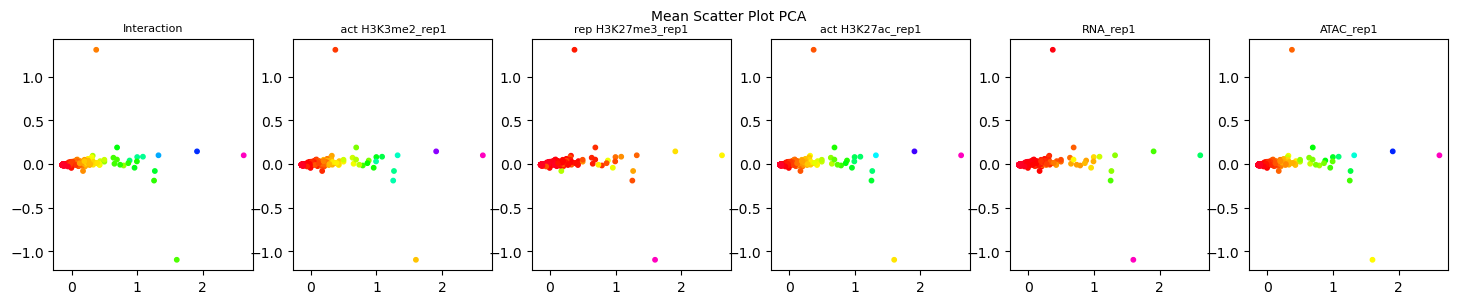

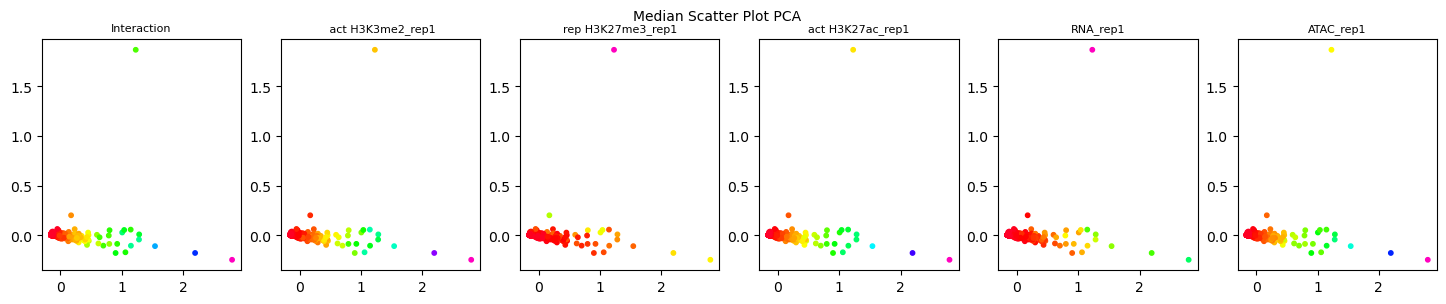

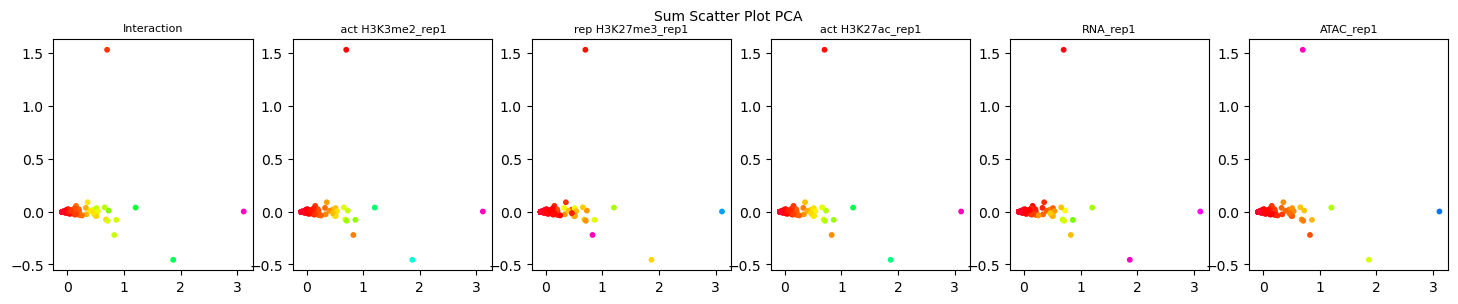

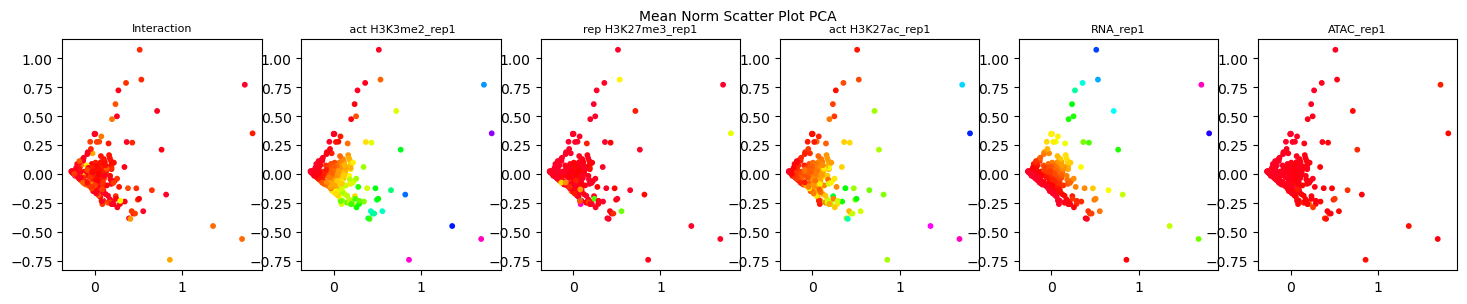

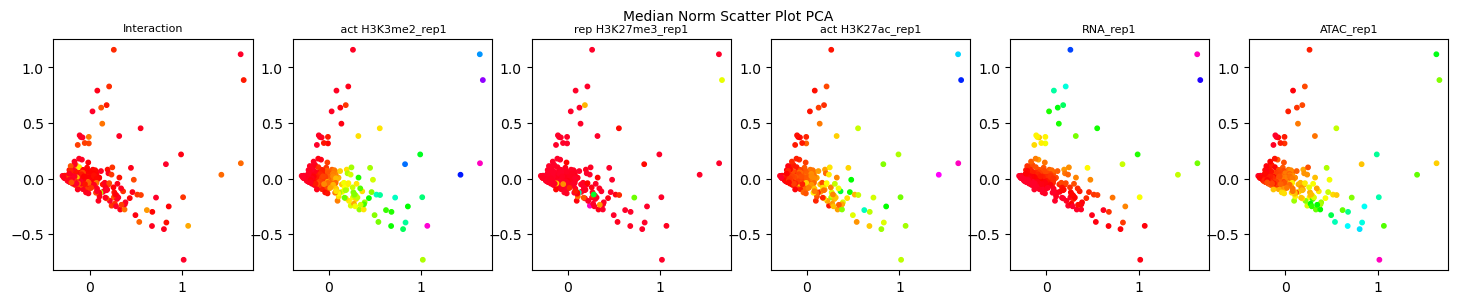

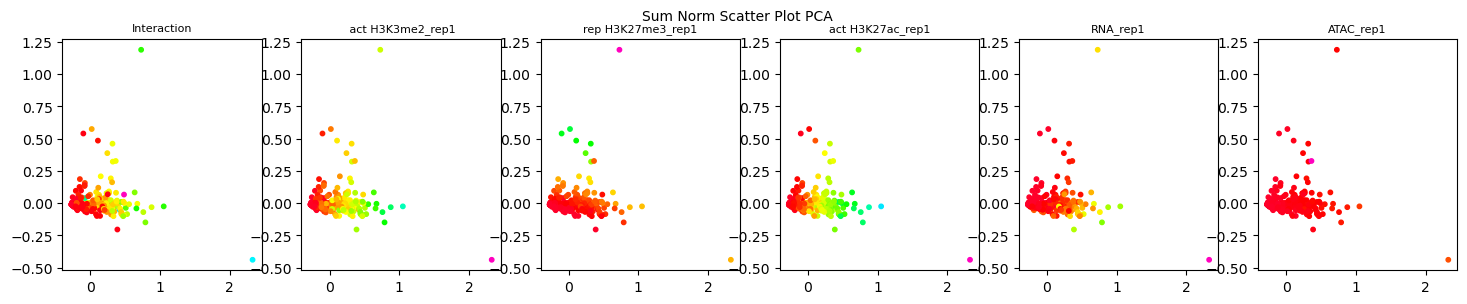

In [ ]:
title = "Scatter Plot PCA"
# list_of_titles = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
list_of_titles = ["Interaction", " act H3K3me2_rep1",  "rep H3K27me3_rep1", "act H3K27ac_rep1","RNA_rep1",  "ATAC_rep1"]
# list_of_colorings = community_matrix_median.T.tolist()

list_of_colorings = community_matrix_median.T[[0,1,3,5,7,10]].tolist()

plotEmbedding([pca1_mean, pca2_mean], list_of_titles, list_of_colorings, "Mean " + title)

list_of_colorings = community_matrix_median.T[[0,1,3,5,7,10]].tolist()
plotEmbedding([pca1_median, pca2_median], list_of_titles, list_of_colorings, "Median " + title)

list_of_colorings = community_matrix_sum.T[[0,1,3,5,7,10]].tolist()
plotEmbedding([pca1_sum, pca2_sum], list_of_titles, list_of_colorings, "Sum " + title)

list_of_colorings = community_matrix_mean_normalized.T[[0,1,3,5,7,10]].tolist()

plotEmbedding([pca1_mean_norm, pca2_mean_norm], list_of_titles, list_of_colorings, "Mean Norm " + title)

list_of_colorings = community_matrix_median_normalized.T[[0,1,3,5,7,10]].tolist()
plotEmbedding([pca1_median_norm, pca2_median_norm], list_of_titles, list_of_colorings, "Median Norm " + title)

list_of_colorings = community_matrix_sum_normalized.T[[0,1,3,5,7,10]].tolist()
plotEmbedding([pca1_sum_norm, pca2_sum_norm], list_of_titles, list_of_colorings, "Sum Norm " + title)

In [ ]:
import umap.umap_ as umap
reducer = umap.UMAP()

In [ ]:
embedding_mean = reducer.fit_transform(community_matrix_mean)
embedding_median = reducer.fit_transform(community_matrix_median)
embedding_sum = reducer.fit_transform(community_matrix_sum)
embedding_mean_norm = reducer.fit_transform(community_matrix_mean_normalized)
embedding_median_norm = reducer.fit_transform(community_matrix_median_normalized)
embedding_sum_norm = reducer.fit_transform(community_matrix_sum_normalized)

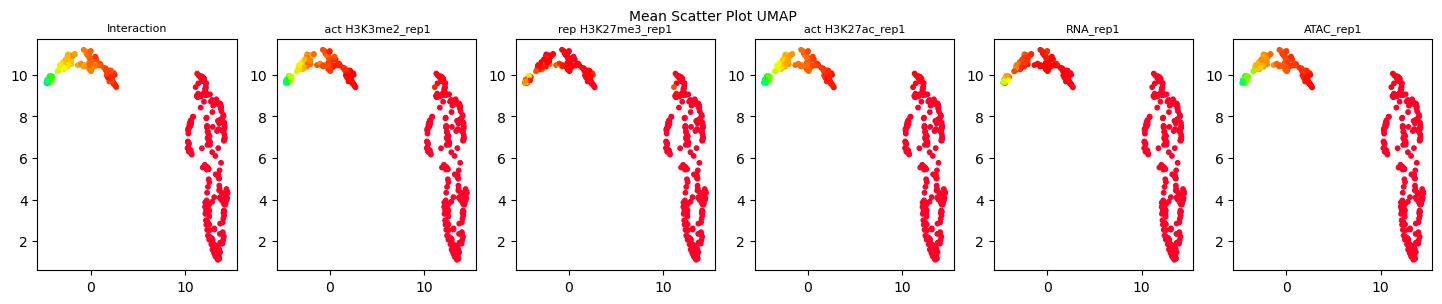

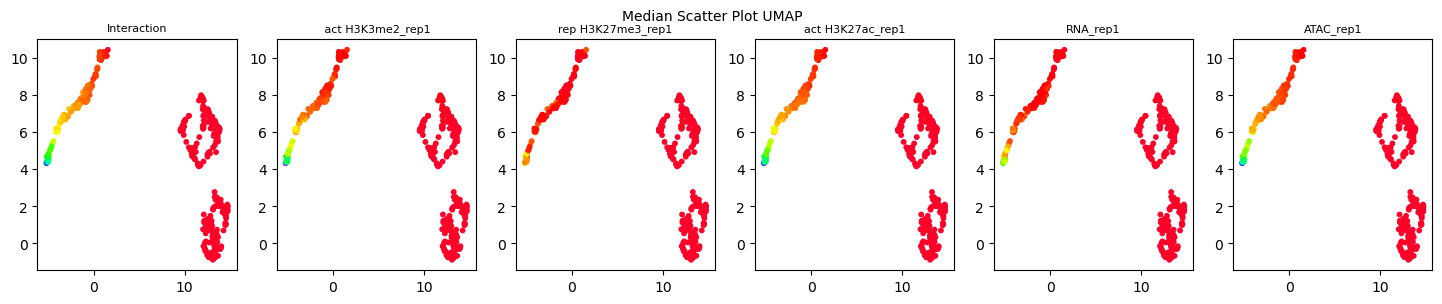

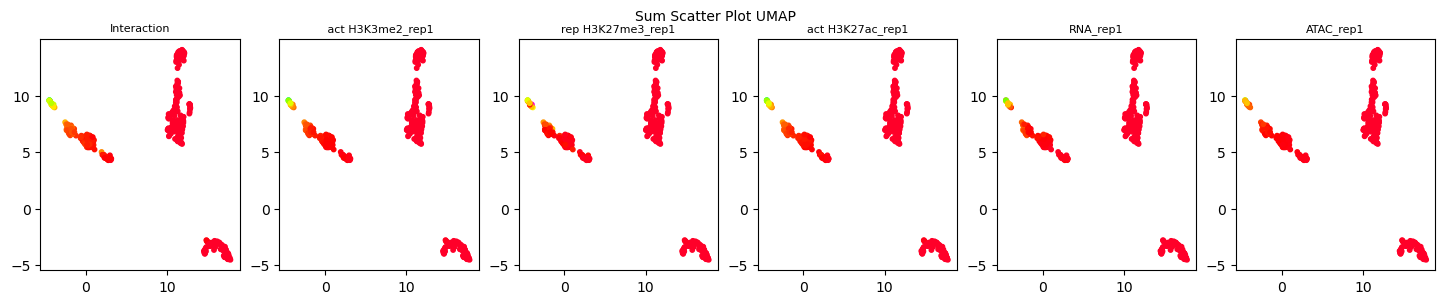

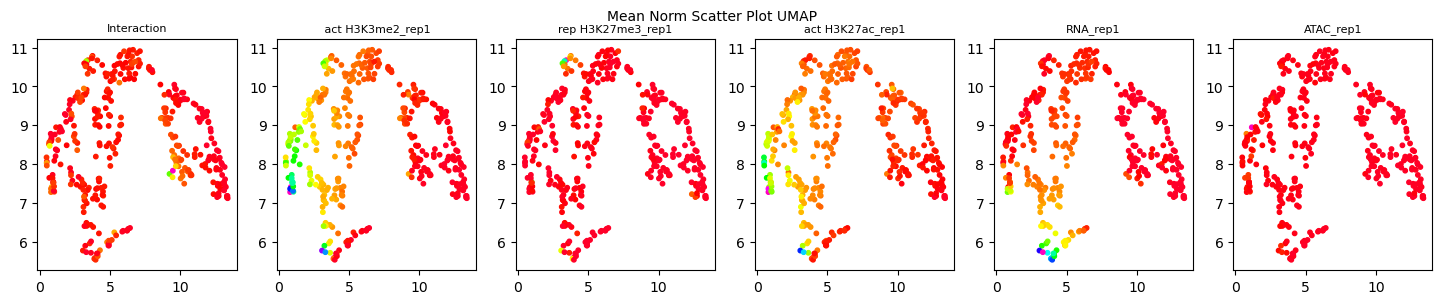

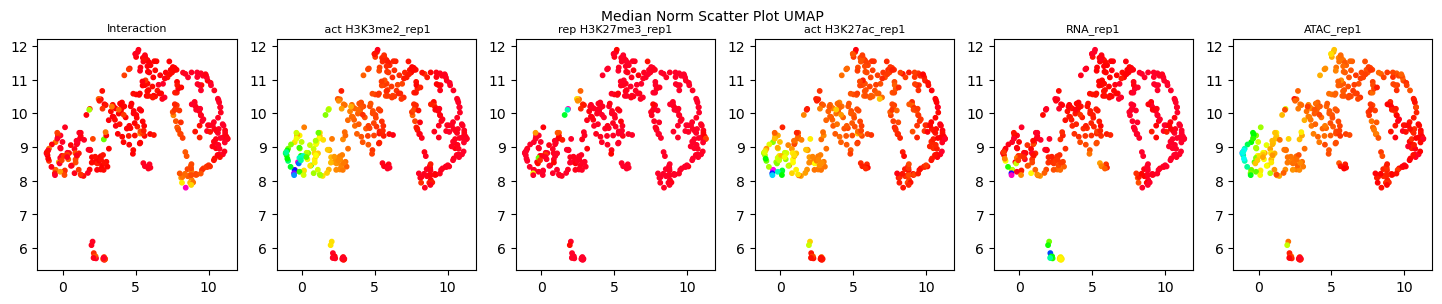

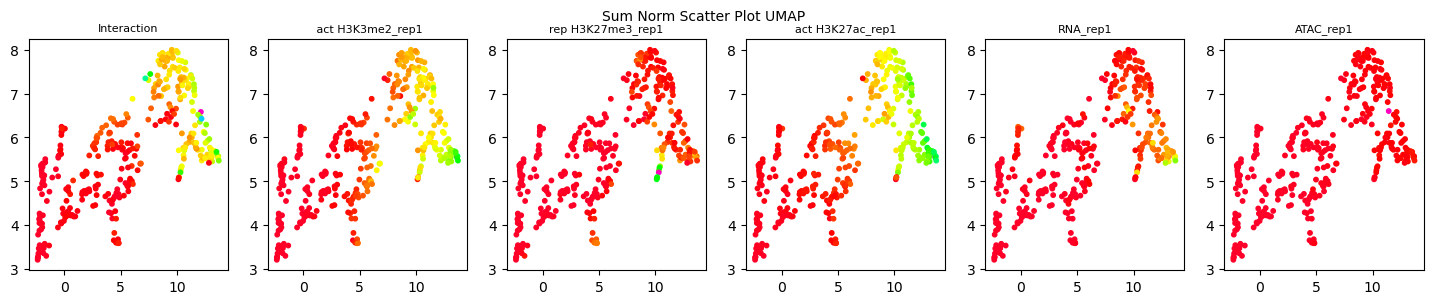

In [ ]:
title = "Scatter Plot UMAP"
# list_of_titles = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
list_of_titles = ["Interaction", " act H3K3me2_rep1",  "rep H3K27me3_rep1", "act H3K27ac_rep1","RNA_rep1",  "ATAC_rep1"]

list_of_colorings = community_matrix_median.T[[0,1,3,5,7,10]].tolist()

plotEmbedding([embedding_mean[:, 0], embedding_mean[:, 1]], list_of_titles, list_of_colorings, "Mean " + title)

list_of_colorings = community_matrix_median.T[[0,1,3,5,7,10]].tolist()
plotEmbedding([embedding_median[:, 0], embedding_median[:, 1]], list_of_titles, list_of_colorings, "Median " + title)

list_of_colorings = community_matrix_sum.T[[0,1,3,5,7,10]].tolist()
plotEmbedding([embedding_sum[:, 0], embedding_sum[:, 1]], list_of_titles, list_of_colorings, "Sum " + title)

list_of_colorings = community_matrix_mean_normalized.T[[0,1,3,5,7,10]].tolist()

plotEmbedding([embedding_mean_norm[:, 0], embedding_mean_norm[:, 1]], list_of_titles, list_of_colorings, "Mean Norm " + title)

list_of_colorings = community_matrix_median_normalized.T[[0,1,3,5,7,10]].tolist()
plotEmbedding([embedding_median_norm[:, 0], embedding_median_norm[:, 1]], list_of_titles, list_of_colorings, "Median Norm " + title)

list_of_colorings = community_matrix_sum_normalized.T[[0,1,3,5,7,10]].tolist()
plotEmbedding([embedding_sum_norm[:, 0], embedding_sum_norm[:, 1]], list_of_titles, list_of_colorings, "Sum Norm " + title)



In [ ]:
def plotEmbedding(list_of_embeddings, list_of_subtitles, list_of_colorings, title_of_plot, fontsize=8):
    fig, axs = plt.subplots(1, len(list_of_subtitles), figsize=(3 * len(list_of_subtitles), 3))

    for i, (title, coloring) in enumerate(zip(list_of_titles, list_of_colorings)):
        # Plot the first version
        axs[i].scatter(list_of_embeddings[0], list_of_embeddings[1], c=coloring, cmap='gist_rainbow', s=10)  # Change the value of s to adjust the dot size
        axs[i].set_title(title, fontsize=fontsize)

    fig.suptitle(title_of_plot, fontsize=fontsize+2)
    plt.show()

In [ ]:
import matplotlib.pyplot as plt

In [ ]:
%matplotlib inline

In [328]:
len(different_communities_Pinna_E_12_5[-1])

469

In [325]:
plt.figure(figsize=(15, 8))
plot_matrix = different_communities_Pinna_E_14_5[-1] - different_communities_Pinna_E_12_5[-1]
sorted_indices = np.argsort(plot_matrix[:, 1])
sorted_matrix = plot_matrix[sorted_indices]
plt.imshow(sorted_matrix, cmap='RdBu_r', interpolation='nearest', aspect='auto')
plt.title('Community Matrix')
plt.xlabel('Matrix Columns')
plt.ylabel('Community ID')
plt.colorbar()

# Add ticks per column with text in 45-degree angle
ticks = ["Interaction", " act H3K3me2_rep1", "act H3K3me2_rep2", "rep H3K27me3_rep1", "rep H3K27me3_rep2", "act H3K27ac_rep1", "act H3K27ac_rep2", "RNA_rep1", "RNA_rep2", "RNA_rep3", "ATAC_rep1", "ATAC_rep2", "ATAC_rep3", "Number of Interactions"]
plt.xticks(range(len(ticks)), ticks, rotation=90, fontsize=8)



ValueError: operands could not be broadcast together with shapes (1962,13) (469,13) 

<Figure size 1500x800 with 0 Axes>

In [ ]:
plt.show()

In [ ]:
elements_per_community

array([ 55., 228., 161., ...,   1.,   1.,   1.])

In [ ]:
np.mean(matrix[community_id, :].tocsr().data)

0.018751868987494782

In [ ]:
matrix[community_id, :].tocsr().data

array([0.00911416, 0.02037817, 0.02676329])

In [ ]:
bw.chroms()

{'chr1': 195471971,
 'chr10': 130694993,
 'chr11': 122082543,
 'chr12': 120129022,
 'chr13': 120421639,
 'chr14': 124902244,
 'chr15': 104043685,
 'chr16': 98207768,
 'chr17': 94987271,
 'chr18': 90702639,
 'chr19': 61431566,
 'chr1_GL456210_random': 169725,
 'chr1_GL456211_random': 241735,
 'chr1_GL456212_random': 153618,
 'chr1_GL456213_random': 39340,
 'chr1_GL456221_random': 206961,
 'chr2': 182113224,
 'chr3': 160039680,
 'chr4': 156508116,
 'chr4_GL456216_random': 66673,
 'chr4_GL456350_random': 227966,
 'chr4_JH584292_random': 14945,
 'chr4_JH584293_random': 207968,
 'chr4_JH584294_random': 191905,
 'chr4_JH584295_random': 1976,
 'chr5': 151834684,
 'chr5_GL456354_random': 195993,
 'chr5_JH584296_random': 199368,
 'chr5_JH584297_random': 205776,
 'chr5_JH584298_random': 184189,
 'chr5_JH584299_random': 953012,
 'chr6': 149736546,
 'chr7': 145441459,
 'chr7_GL456219_random': 175968,
 'chr8': 129401213,
 'chr9': 124595110,
 'chrM': 16299,
 'chrUn_GL456239': 40056,
 'chrUn_GL456359